# Test Code Execution with Energy Profiling

In [1]:
# Import modules
import lassi.code_manager
from lassi.format_colors import color

In [2]:
# Code to test
folder = "test_codes/lid"
code_filename = "lid-driven-cavity-cuda_main.cu"
exe_input_parameters = [""]

# Parameters
power_measure = True

source_language = "CUDA"
target_language = "CUDA"
build_script = False
code_compiler = "nvcc"
code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_60 -O3"

In [3]:
compile_result, execute_file = lassi.code_manager.compile_code(
    folder + '/' + code_filename,
    source_language,
    code_compiler,
    code_compiler_kwds
)

Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_60', '-O3', 'test_codes/lid/lid-driven-cavity-cuda_main.cu', '-o', 'test_codes/lid/lid-driven-cavity-cuda_main']

Compilation of code successful!


Waiting for the system to settle down...: 100%|████████████████████████████████████████████████████████| 10/10 [00:10<00:00,  1.00s/it]


Working directory: test_codes/lid
Execute command: ['./lid-driven-cavity-cuda_main', '']

Problem size: 512 x 512 
Time = 0.000477, delt = 4.768372e-04, iter = 92522, res = 9.999751e-04
Time = 0.000954, delt = 4.768372e-04, iter = 88410, res = 9.999561e-04
Time = 0.001000, delt = 4.632568e-05, iter = 86674, res = 9.999808e-04

Total execution time of the iteration loop: 20.689363 (s)
GPU power data has been written to CUDA_CUDA_gpu_power_results.csv


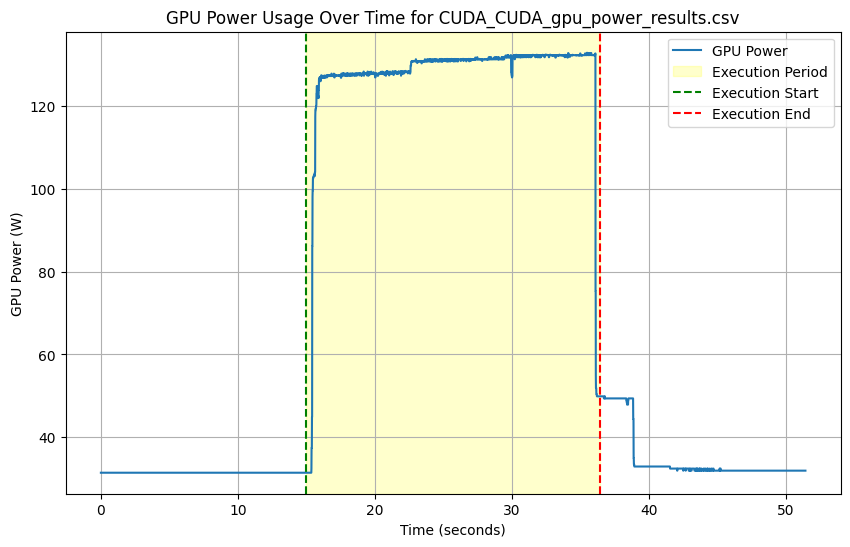

Start time: 15.001 -- End time: 36.438
Code execution duration: 21.44 seconds
Total GPU energy consumption for CUDA_CUDA_gpu_power_results.csv:
  0.000760 kWh
  0.7601 Wh
  2736.45 J
Average GPU power: 127.80 W
Total Energy During Exe Runtime:   2736.45 J
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!


In [4]:
execute_result, exe_output_source, total_energy_joules, ave_power, duration = lassi.code_manager.execute_code(
    execute_file,
    exe_input_parameters,
    power_measure,
    source_language,
    target_language,
    build_script
)

Measure system idle power...
Duration for idle time measurement: 21.44
GPU power data has been written to idle__gpu_power_results.csv


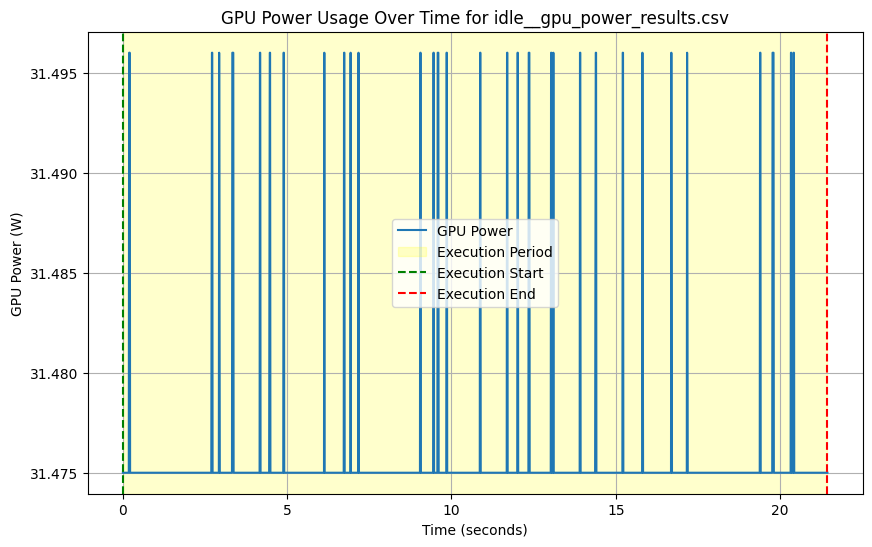

Start time: 0 -- End time: 21.437
Code execution duration: 21.44 seconds
Total GPU energy consumption for idle__gpu_power_results.csv:
  0.000187 kWh
  0.1874 Wh
  674.57 J
Average GPU power: 31.48 W
Total Energy During Exe Runtime:   674.57 J
----------------------------------------------------------------------------------------------------------------------------------------


Actual measured values during runtime for lid-driven-cavity-cuda_main.cu
Average GPU power: 96.32 W
Total Energy During Exe Runtime:   2061.88 J


In [6]:
# Measure system idle power
print("Measure system idle power...")
idle_energy_joules, idle_ave_power = lassi.get_power.idlepower(duration)
actual_energy = total_energy_joules - idle_energy_joules
actual_ave_power = ave_power - idle_ave_power
print(color.BOLD + color.BLUE + "\nActual measured values during runtime for " + color.END + str(code_filename))
print("Average GPU power: " + color.BOLD + f"{actual_ave_power:.2f} W" + color.END)
print("Total Energy During Exe Runtime: " + color.BOLD + f"{actual_energy:.2f} J" + color.END)